# EmoWOZ — SVM, BiGRU and BiLSTM
Workstreams 2/3 in-domain extension using native labels. Training is run separately with `scripts/train_emowoz_baselines.py`. No test-driven configuration changes.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
import json

import pandas as pd
from IPython.display import Image, display

## Labelled targets and dev-only choices
Only user turns are scored; system turns are not neutral labels. RNN architecture selection is frozen before test evaluation.

In [2]:
from emotionshift.data.labels import emotions

print("Native labels:", emotions("emowoz"))
for path in ["reports/b1/emowoz/selection.json", "reports/b2/emowoz/selection.json"]:
    display(json.loads(Path(path).read_text()))

Native labels: ['neutral', 'fearful', 'dissatisfied', 'apologetic', 'abusive', 'excited', 'satisfied']


{'config': {'C': 0.3,
  'class_weight': 'balanced',
  'features': 'word+char',
  'classifier': 'svm'},
 'selected_on': 'dev only',
 'metric': 'weighted_f1_no_neutral',
 'dev_score': 0.773310167554837,
 'test_used_for_selection': False}

{'selected_model': 'b2_bilstm',
 'dev_means': {'b2_bilstm': 0.7817279462693211,
  'b2_bigru': 0.7812143121686612},
 'metric': 'weighted_f1_no_neutral',
 'rule': 'mean best-dev across five seeds; config-order ties',
 'test_used_for_selection': False}

## Development learning curves
Dots mark each seed's best dev epoch, not the final training epoch. Architecture selection averages these best-dev scores; test results do not determine the checkpoint.

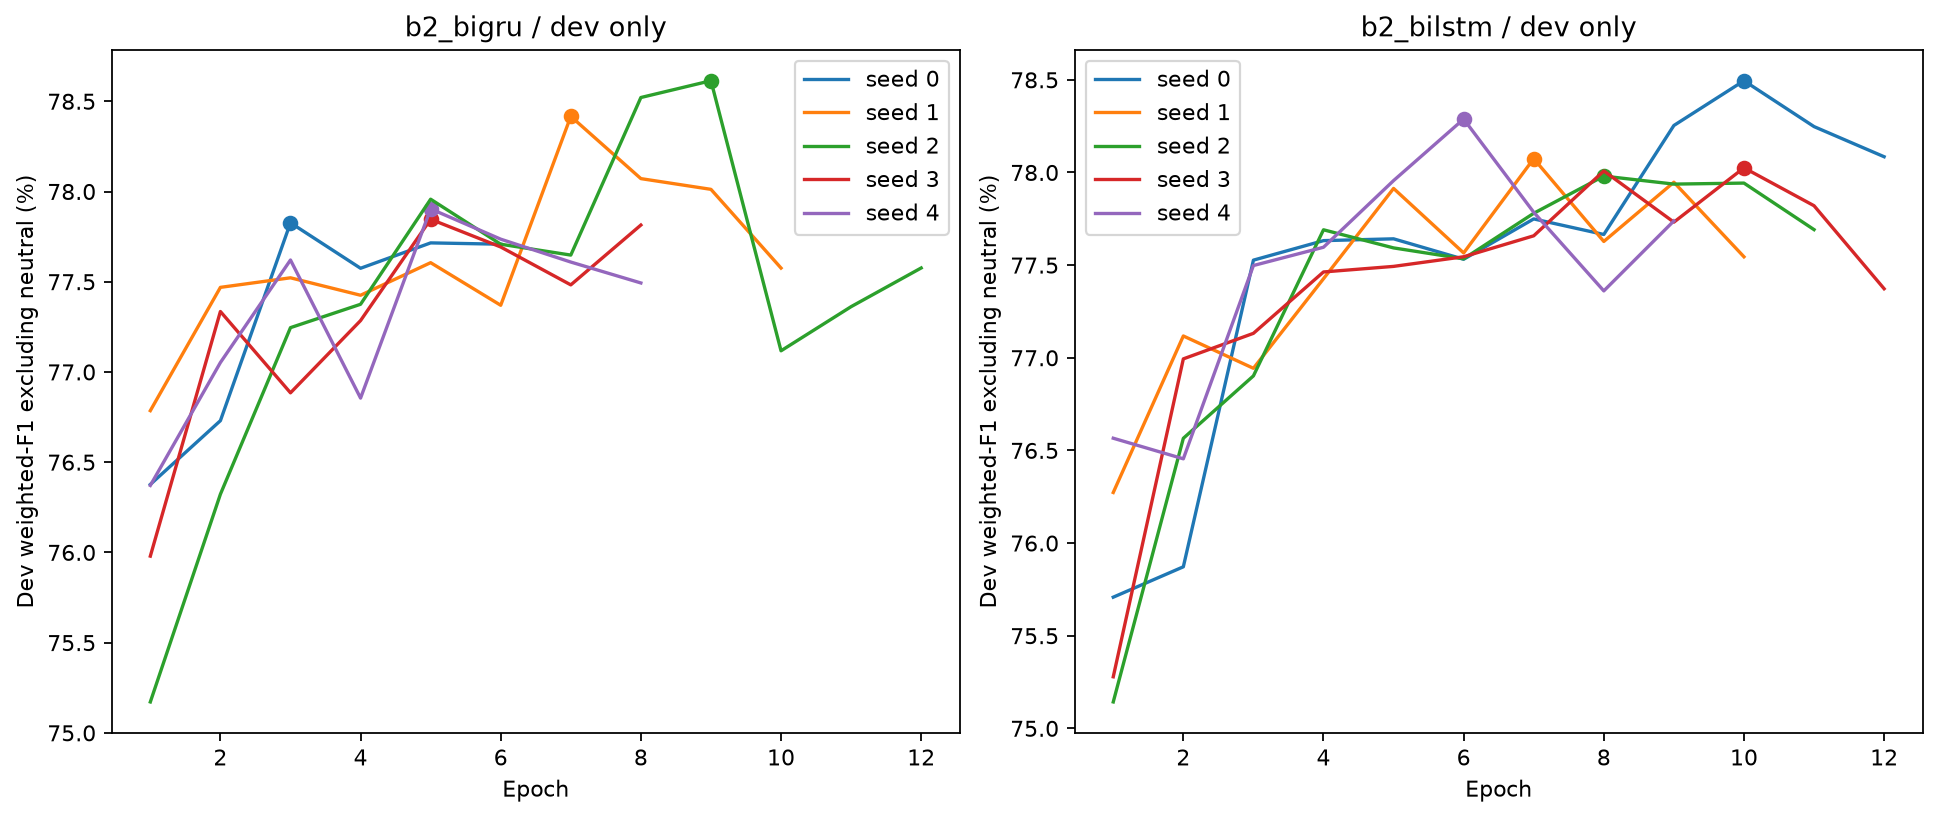

In [3]:
display(Image(filename="reports/emowoz_baselines/figures/learning_curves.png"))

## Main test results
Five-seed means and population SD; 1,000-resample dialogue CI for seed 0, not seed-mean uncertainty.

,model,n,headline,std,ci_low,ci_high,macro_f1_no_neutral,macro_f1,derived_shift_f1
0,b1,8634,0.764975,0.000000,0.745574,0.782777,0.471027,0.533918,0.743627
1,b2_bigru,8634,0.770529,0.004528,0.748536,0.781185,0.482423,0.542609,0.739284
2,b2_bilstm,8634,0.770060,0.001909,0.748894,0.785174,0.487349,0.547008,0.741249


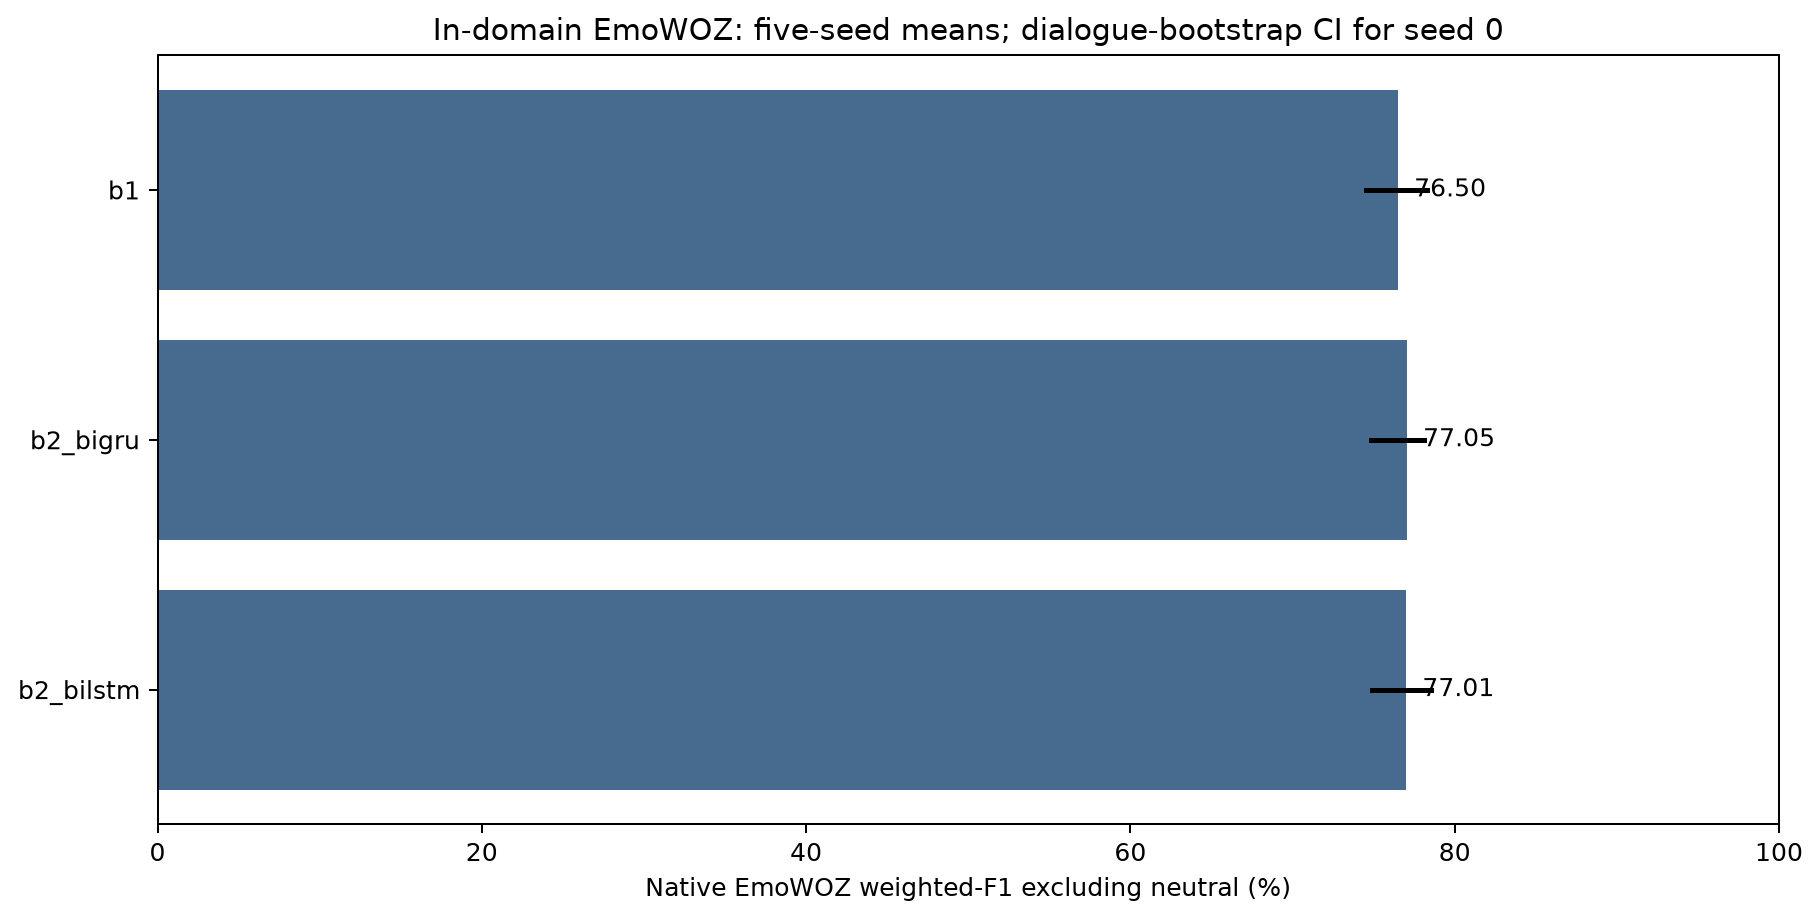

In [4]:
display(pd.read_csv("reports/emowoz_baselines/comparison.csv"))
display(Image(filename="reports/emowoz_baselines/figures/headline_comparison.png"))

## First / stable / shift
Gold shift labels are evaluation metadata and are not model inputs.

,model,group,weighted_f1_no_neutral
0,b1,first,0.489712
1,b1,stable,0.673813
2,b1,shift,0.819310
3,b2_bigru,first,0.448338
4,b2_bigru,stable,0.687220
5,b2_bigru,shift,0.828274
6,b2_bilstm,first,0.445490
7,b2_bilstm,stable,0.681308
8,b2_bilstm,shift,0.830054


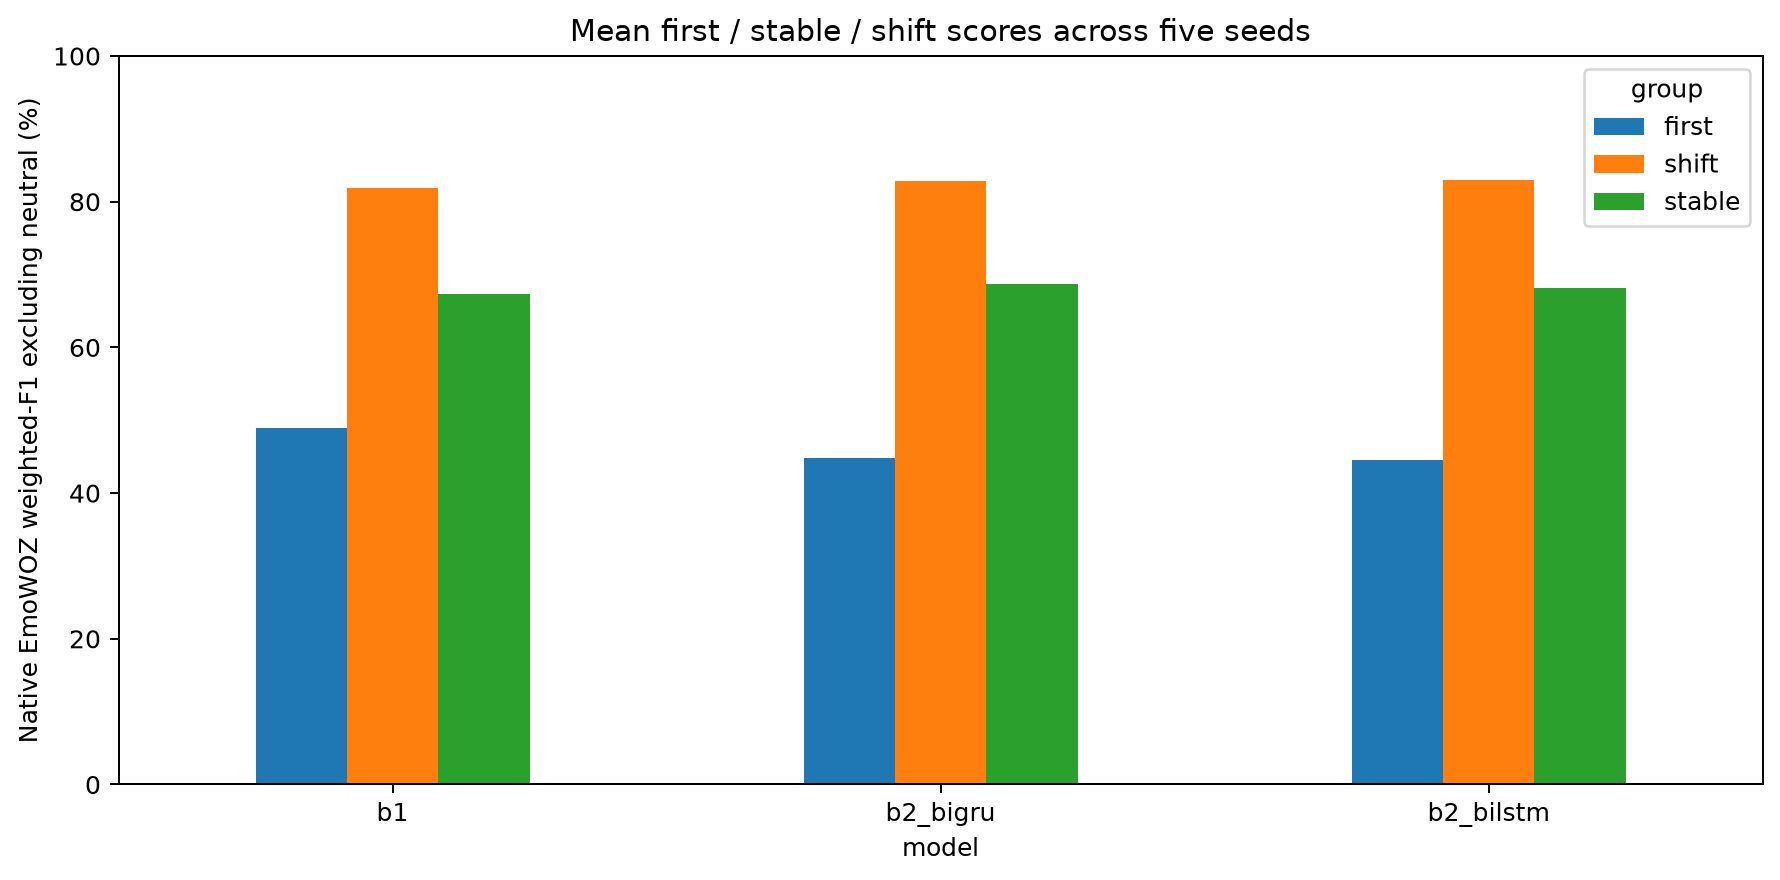

In [5]:
display(pd.read_csv("reports/emowoz_baselines/figures/strata.csv"))
display(Image(filename="reports/emowoz_baselines/figures/strata.png"))

## Checkpoint demo
Probabilities follow the native EmoWOZ label order; SVM probabilities are softmax scores, not calibrated confidences.

In [6]:
from emotionshift.models.birnn import BiRNNBaseline

selection = json.loads(Path("reports/b2/emowoz/selection.json").read_text())
name = selection["selected_model"]
model = BiRNNBaseline.load(f"models/{name}_emowoz_seed0.pt")
texts = ["Thank you, that is exactly what I needed.", "You are not listening to my request."]
print(model.labels)
print(model.predict(texts))
display(model.predict_proba(texts))

['neutral', 'fearful', 'dissatisfied', 'apologetic', 'abusive', 'excited', 'satisfied']
['satisfied', 'excited']


array([[1.78420218e-03, 1.26772443e-06, 1.59539297e-04, 1.13134565e-05,
        8.28672512e-07, 6.25960020e-05, 9.97980297e-01],
       [4.06730808e-02, 9.16482210e-02, 1.18569233e-01, 2.25267019e-02,
        2.97902107e-01, 4.16861892e-01, 1.18186520e-02]], dtype=float32)

## Verification and limits
Native EmoWOZ scores are not numerically comparable to Ekman-label benchmarks. These are utterance-only models, without system or dialogue history. See results.md for source attribution and runtime details.

In [7]:
verification = json.loads(Path("reports/emowoz_baselines/verification.json").read_text())
print("Prediction CSVs audited:", verification["prediction_csvs"])
print("Dev selection verified:", verification["dev_selection_verified"])

Prediction CSVs audited: 15
Dev selection verified: True
